# Module 11 — Capstone: Which Method When

Part of the Causal Inference Playbook. Course program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

- What this module does: it builds no new method. It runs side by side the methods that compare men who took a job-training program with men who didn't, and then gives a guide for choosing a method from the shape of the data: what the data holds, such as a cutoff on a score, measures before and after, or only columns measured before.
- The question: an analyst without an experiment has several methods to choose from. Which method should the analyst use, and when?
- Bias: how far a method's estimate would land from the program's true effect on average, over many reruns with new men. Chance moves each single estimate around that average. A method with no bias lands on the true effect on average.
- The example: the NSW (National Supported Work) job-training program let applicants in by a lottery. The lottery, not the men, decided who got in, so the men it let in and the applicants it kept out (the lottery men) differ only by chance. So comparing the two groups gives a right answer for the program's effect, with no bias.
- Part 1, the scoreboard: each method, run on the same men who took the program, once with each of two comparison groups: groups of men who didn't take the program, whose earnings each method uses to estimate what the men who took it would have earned without it. The two comparison groups are men from two US surveys: the PSID (Panel Study of Income Dynamics) men and the CPS (Current Population Survey) men. Each estimate is set against the right answer.
- Part 2, the guide: each shape of data, the method it allows, what must be true for that method's estimate to have no bias, and the check that tests it.
- Two kinds of steps, each with a tag at its top:
  - [in real life]: a step an analyst without a lottery runs.
  - [only in this module]: a step that uses the lottery men or the right answer, which a real analyst doesn't have, to grade the methods.

## From the curriculum

> ## <u>Module 11 — Capstone: Which Method When</u>
>
> **Concepts**
>
> This notebook has two parts.
> - Part 1, the scoreboard: grades methods against the right answer. Grading
>   needs a right answer, and of the playbook's five datasets, only the
>   job-training data has one, from its lottery.
> - Part 2, the guide: helps choose a method. In real life there is no right
>   answer, so the choice comes from the data's shape.
>
> | Method | Data shape it needs | Part 1: graded | Part 2: in the guide | Why |
> |---|---|---|---|---|
> | Randomized experiment | units the analyst can split by chance | no | yes | it is the right answer |
> | Naive gap | any two groups | yes | no | the starting line, with no correction |
> | Regression adjustment | columns measured before the treatment | yes | yes | |
> | Matching | the same | yes | yes | |
> | Weighting | the same | yes | yes | |
> | Doubly robust (regression adjustment with weighting) | the same | yes | yes | |
> | DiD | the outcome measured before and after, for both groups | yes | yes | |
> | DiD with weighting | the same | yes | yes | in the guide, a version of DiD |
> | IV (instrumental variables) | an instrument: something that changes who gets the treatment and affects the outcome in no other way | no | yes | the job-training data has no instrument |
> | RDD (regression discontinuity design) | a cutoff on a score that decides who gets the treatment | no | yes | the job-training data has no cutoff |
> | Synthetic control | one treated unit and many untreated units | no | yes | the job-training data has no single treated unit |
>
> Each method in Part 1 runs once with each of the two comparison groups.
>
> - The right answer's own uncertainty: the right answer is itself an estimate
>   from 185 treated men and 260 lottery men, so it has a 95% confidence
>   interval. A method's estimate that lands inside that interval can't be shown
>   wrong by the right answer, because the true effect could be anywhere inside
>   the interval, even at the method's estimate.
> - Each method's assumption: what must be true for the method's estimate to
>   have no bias, and the check that can test it.
>
> **Why it matters**
> No method is right everywhere. The method closest to the right answer with
> one comparison group isn't the closest with another, and a method's
> assumption can hold with one comparison group and fail with another. So an analyst picks the methods
> the data's shape allows, runs each, and trusts an estimate only as far as its
> method's assumption survives its checks.
>
> **Worked example**
> The NSW (National Supported Work) job-training program, with two comparison
> groups: the PSID (Panel Study of Income Dynamics) men and the CPS (Current
> Population Survey) men. Seven methods on each group, the scoreboard against
> the right answer, then a guide that maps each data shape to its method, its
> assumption and its check.
>
> **Resources**
> - [LaLonde (1986), "Evaluating the Econometric Evaluations of Training Programs with Experimental Data"](https://www.jstor.org/stable/1806062)
>   (American Economic Review 76(4), link checked): the paper that first ran
>   non-experimental methods on the NSW data against the lottery's answer.
> - [Imbens and Xu (2024), "LaLonde (1986) after Nearly Four Decades: Lessons Learned"](https://arxiv.org/abs/2406.00827)
>   (arXiv, link checked; later retitled "Comparing Experimental and
>   Nonexperimental Methods"): what four decades of methods on the same data
>   taught. First among them: overlap, meaning that each man who took the
>   program has similar men who didn't.
>
> **Exercise type:** five product cases, each with its data described. For each,
> pick the method, say what must be true, and name the check. Fully worked.
>
> **Interview angle:** "Two methods on the same data give 2% and 9%. Which one
> do you report?"

## The data

The NSW (National Supported Work) job-training program, from the file by Rajeev Dehejia and Sadek Wahba. Each row is one man. Four groups of men:
- The treated men: 185 men who applied for NSW, were let in by a lottery, and took the program in 1976 or 1977.
- The lottery men: 260 men who applied for NSW like the treated men, but whom the lottery kept out. The lottery, not the men, decided who got in, so the treated men and the lottery men differ only by chance, and the lottery men show what the treated men would have earned without the program.
- The PSID men: 2,490 men from the PSID (Panel Study of Income Dynamics), a US survey. None of them took the program.
- The CPS men: 15,992 men from the CPS (Current Population Survey), another US survey. None of them took the program.

The columns: age and years of education. Four yes/no columns (1 = yes, 0 = no): black, hispanic, married and no high-school degree. Earnings in 1974 and in 1975, both before the program, and in 1978, after the program. Earnings are in US dollars per year.

The PSID men and the CPS men are the two comparison groups, each paired with the same 185 treated men. Each method below uses one comparison group at a time.

The output counts each group and checks that no row has a missing value, because the methods below drop such rows without saying so, and every man should count.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

import common

experiment = common.load_lalonde("experimental")  # 185 treated men (treat = 1) and 260 lottery men (treat = 0)
psid = common.load_lalonde("psid")                # 185 treated men (treat = 1) and 2,490 PSID men (treat = 0)
cps = common.load_lalonde("cps")                  # 185 treated men (treat = 1) and 15,992 CPS men (treat = 0)
experiment, psid, cps = (df.astype({c: "float64" for c in df.columns if c != "treat"}) for df in (experiment, psid, cps))
treated, lottery = experiment[experiment.treat == 1], experiment[experiment.treat == 0]
COLUMNS = ["age", "education", "black", "hispanic", "married", "nodegree", "re74", "re75"]
r1 = lambda x: round(float(x), 1)
num = lambda x, d=1: f"{x:,.{d}f}".replace("-", "−")  # printed numbers use the minus sign "−"

print(f"Treated men = {len(treated)}")
print(f"Lottery men = {len(lottery)}")
print(f"PSID men = {(psid.treat == 0).sum():,}")
print(f"CPS men = {(cps.treat == 0).sum():,}")
print(f"Rows with a missing value = {sum(df.isna().any(axis=1).sum() for df in (experiment, psid, cps))}")

Treated men = 185
Lottery men = 260
PSID men = 2,490
CPS men = 15,992
Rows with a missing value = 0


## The right answer

**[only in this module]** The right answer comes from the lottery: the treated men's mean 1978 earnings minus the lottery men's mean 1978 earnings. The lottery made the two groups differ only by chance, so the difference has no bias: only chance moves it away from the program's true effect.

In [2]:
mean_t, mean_l = r1(treated.re78.mean()), r1(lottery.re78.mean())
RIGHT = r1(mean_t - mean_l)
print(f"Right answer ({len(treated)} treated men, {len(lottery)} lottery men)")
print("    = (treated men's mean 1978 earnings) − (lottery men's mean 1978 earnings)")
print(f"    = {num(mean_t)} − {num(mean_l)} = {num(RIGHT)}")

Right answer (185 treated men, 260 lottery men)
    = (treated men's mean 1978 earnings) − (lottery men's mean 1978 earnings)
    = 6,349.1 − 4,554.8 = 1,794.3


**[only in this module]** The right answer is itself an estimate, from 185 treated men and 260 lottery men, so chance moves it too. Its 95% confidence interval shows how far: a range built so that, in 95 of 100 reruns of the lottery, the range built from that rerun holds the program's true effect. The interval matters for the scoreboard below, because the interval doesn't say where inside the interval the true effect is.

**formula**: interval = right answer ± (1.96 × standard error)

**formula**: standard error = square root of [(variance of the treated men's 1978 earnings ÷ 185) + (variance of the lottery men's 1978 earnings ÷ 260)]

**formula**: a group's variance = (sum of each man's squared distance from his group's mean 1978 earnings) ÷ (number of men − 1)

- The standard error measures how far chance typically moves the right answer.
- Chance in a difference of two means from this many men spreads in a bell shape. Within 1.96 standard errors of the middle, on both sides together, lies 95% of a bell-shaped spread, with 2.5% beyond each side.
- The variance divides by (number of men − 1), not the number of men, because the men's distances from their group's mean always add up to 0. Once all distances but one are known, the last one is fixed, so only (number of men − 1) of the distances are free.

In [3]:
var = {}
for name, group in [("treated men", treated), ("lottery men", lottery)]:
    squares = r1(((group.re78 - group.re78.mean()) ** 2).sum())
    var[name] = r1(squares / (len(group) - 1))
    print(f"Variance of the {name}'s 1978 earnings ({len(group)} men)")
    print("    = (sum of squared distances from the mean) ÷ (number of men − 1)")
    print(f"    = {num(squares)} ÷ {len(group) - 1} = {num(var[name])}")
    print()

Variance of the treated men's 1978 earnings (185 men)
    = (sum of squared distances from the mean) ÷ (number of men − 1)
    = 11,388,867,146.7 ÷ 184 = 61,896,017.1

Variance of the lottery men's 1978 earnings (260 men)
    = (sum of squared distances from the mean) ÷ (number of men − 1)
    = 7,788,766,438.3 ÷ 259 = 30,072,457.3



In [4]:
se = r1(np.sqrt(var["treated men"] / len(treated) + var["lottery men"] / len(lottery)))
print("Standard error of the right answer")
print(f"    = square root of [(variance of the treated men's 1978 earnings ÷ {len(treated)}) + (variance of the lottery men's 1978 earnings ÷ {len(lottery)})]")
print(f"    = square root of [({num(var['treated men'])} ÷ {len(treated)}) + ({num(var['lottery men'])} ÷ {len(lottery)})] = {num(se)}")

Standard error of the right answer
    = square root of [(variance of the treated men's 1978 earnings ÷ 185) + (variance of the lottery men's 1978 earnings ÷ 260)]
    = square root of [(61,896,017.1 ÷ 185) + (30,072,457.3 ÷ 260)] = 671.0


In [5]:
HALF = r1(1.96 * se)
LOW, HIGH = r1(RIGHT - HALF), r1(RIGHT + HALF)
print("Half-width of the right answer's 95% confidence interval")
print(f"    = 1.96 × {num(se)} = {num(HALF)}")
print()
print("Right answer's 95% confidence interval")
print("    = right answer ± half-width")
print(f"    = {num(RIGHT)} ± {num(HALF)} = {num(LOW)} to {num(HIGH)}")

Half-width of the right answer's 95% confidence interval
    = 1.96 × 671.0 = 1,315.2

Right answer's 95% confidence interval
    = right answer ± half-width
    = 1,794.3 ± 1,315.2 = 479.1 to 3,109.5


**Observation:** the right answer is $1,794.3, and its 95% confidence interval runs from $479.1 to $3,109.5.

Chosen example: the true effect could be $800.0, inside the interval. Then an estimate of $790.0 would be closer to the true effect than an estimate of $1,790.0, though the second is closer to the right answer.

**Conclusion:** the right answer can't rank estimates that land inside its interval.

## Part 1: the scoreboard

### The seven methods

Each method uses the treated men, one comparison group, and the same 8 columns: age, years of education, black, hispanic, married, no high-school degree, 1974 earnings and 1975 earnings. Each estimates the program's effect on the treated men's 1978 earnings: (the treated men's actual 1978 earnings) − (their 1978 earnings without the program). The methods differ in where they take the treated men's earnings without the program from, so each rests on a different assumption.

Two terms the table uses, defined here so the table's cells can stay short: the propensity score, in the matching and weighting rows, and the earnings formula, in the regression adjustment row.
- The propensity score is the share of treated men among men with similar columns. A logistic regression, a fitting function for a yes/no column, fits it: it predicts "took the program" (yes/no) from the 8 columns and returns each man's score. A score near 1 means men with his columns are mostly treated men, and a score near 0 means they are mostly comparison men.
- The earnings formula: a formula that predicts a man's 1978 earnings from his 8 columns. Regression adjustment, the table's second row, fits it. A comparison man's error = (his actual 1978 earnings) − (his 1978 earnings predicted by the earnings formula).

| Method | The treated men's earnings without the program are taken from | What must be true |
|---|---|---|
| Naive gap | the comparison men's mean 1978 earnings | the two groups would have earned the same without the program |
| Regression adjustment | the earnings formula, fitted on the comparison men | every difference between the groups that affects 1978 earnings has a column, and each column changes 1978 earnings by the same amount per step at every level |
| Matching | the comparison man with the closest propensity score | every such difference has a column, and each treated man has comparison men with a similar score |
| Weighting | the comparison men's weighted mean 1978 earnings, in which comparison men with columns like the treated men's count more | every such difference has a column, and each treated man has comparison men with a similar score |
| Doubly robust | regression adjustment, corrected with weighting | what regression adjustment needs or what weighting needs: only one of the two has to hold |
| DiD (difference-in-differences) | the treated men's 1975 earnings plus the comparison men's change from 1975 to 1978 | the parallel-trends assumption: without the program, the treated men's earnings would have changed by as much as the comparison men's |
| DiD with weighting | as for DiD, with the comparison men's change weighted | parallel trends among the comparison men whose columns are like the treated men's |

The next code cell defines the seven methods. It prints nothing: each later output prints one method's formula in words and then its numbers.

In [6]:
def groups(data):
    return data[data.treat == 1], data[data.treat == 0]

def scores(data):
    # Each man's propensity score, from a logistic regression on the 8 columns, and each comparison man's weight.
    score = smf.logit("treat ~ " + " + ".join(COLUMNS), data).fit(disp=0).predict(data)
    t, c = groups(data)
    weight = score[c.index] / (1 - score[c.index])
    return score[t.index].to_numpy(), score[c.index].to_numpy(), weight.to_numpy()

def predictions(data):
    # The earnings formula, fitted on the comparison men; returns the predicted 1978 earnings of the treated men and of the comparison men.
    t, c = groups(data)
    fit = smf.ols("re78 ~ " + " + ".join(COLUMNS), c).fit()
    return fit.predict(t).to_numpy(), fit.predict(c).to_numpy()

def header(name, data, label):
    t, c = groups(data)
    print(f"{name} estimate ({len(t)} treated men, {len(c):,} {label} men)")

ESTIMATES = {}
NICE = {"age": "age", "education": "years of education", "black": "black", "hispanic": "hispanic", "married": "married",
        "nodegree": "no high-school degree", "re74": "1974 earnings", "re75": "1975 earnings"}
NAMES = ["Naive gap", "Regression adjustment", "Matching", "Weighting", "Doubly robust", "DiD", "DiD with weighting"]

def line_naive(data, label):
    t, c = groups(data)
    a, b = r1(t.re78.mean()), r1(c.re78.mean())
    header("Naive gap", data, label)
    print(f"    = (treated men's mean 1978 earnings) − ({label} men's mean 1978 earnings)")
    print(f"    = {num(a)} − {num(b)} = {num(r1(a - b))}")
    ESTIMATES[(label, "Naive gap")] = r1(a - b)

def line_regression(data, label):
    t, c = groups(data)
    fit = smf.ols("re78 ~ " + " + ".join(COLUMNS), c).fit()
    start = r1(fit.params["Intercept"])
    rows = [("starting number", "", "", num(start))]
    total = start
    for col in COLUMNS:
        coef, mean = round(float(fit.params[col]), 6), round(float(t[col].mean()), 6)
        product = r1(coef * mean)
        total += product
        rows.append((NICE[col], num(coef, 6), num(mean, 6), num(product)))
    b = r1(total)
    print(f"Treated men's mean predicted 1978 earnings without the program (formula fitted on {len(c):,} {label} men)")
    print("    = starting number + (each column's number × treated men's mean in that column), added over the 8 columns")
    print()
    common.show(pd.DataFrame(rows, columns=["column", "column's number", "treated men's mean", "product"]))
    print()
    print(f"    sum of the last column = {num(b)}")
    print()
    a = r1(t.re78.mean())
    header("Regression adjustment", data, label)
    print("    = (treated men's mean 1978 earnings) − (treated men's mean predicted 1978 earnings)")
    print(f"    = {num(a)} − {num(b)} = {num(r1(a - b))}")
    ESTIMATES[(label, "Regression adjustment")] = r1(a - b)

def line_matching(data, label):
    t, c = groups(data)
    s_t, s_c, _ = scores(data)
    distance = np.abs(s_t[:, None] - s_c[None, :])
    closest = distance <= distance.min(axis=1, keepdims=True) + 1e-12  # scores equal up to rounding count as tied
    match = (closest / closest.sum(axis=1, keepdims=True)) @ c.re78.to_numpy()
    a, b = r1(t.re78.mean()), r1(match.mean())
    header("Matching", data, label)
    print("    = (treated men's mean 1978 earnings) − (mean of the matches' 1978 earnings)")
    print(f"    = {num(a)} − {num(b)} = {num(r1(a - b))}")
    print(f"    note: {num(b)} is the mean of the {len(t)} treated men's match values.")
    print("    note: a treated man's match value is his match's 1978 earnings, or the mean of his tied matches'.")
    ESTIMATES[(label, "Matching")] = r1(a - b)

def weighted_mean(values, weight):
    top, bottom = r1((weight * values).sum()), round(float(weight.sum()), 3)
    return top, bottom, r1(top / bottom)

def line_weighting(data, label):
    t, c = groups(data)
    _, _, w = scores(data)
    top, bottom, wmean = weighted_mean(c.re78.to_numpy(), w)
    a = r1(t.re78.mean())
    print(f"{label} men's weighted mean 1978 earnings ({len(c):,} men)")
    print("    = (sum of (weight × 1978 earnings)) ÷ (sum of the weights)")
    print(f"    = {num(top)} ÷ {num(bottom, 3)} = {num(wmean)}")
    print(f"    note: each sum adds one term for each of the {len(c):,} {label} men.")
    print()
    header("Weighting", data, label)
    print(f"    = (treated men's mean 1978 earnings) − ({label} men's weighted mean 1978 earnings)")
    print(f"    = {num(a)} − {num(wmean)} = {num(r1(a - wmean))}")
    ESTIMATES[(label, "Weighting")] = r1(a - wmean)

def line_doubly(data, label):
    t, c = groups(data)
    _, _, w = scores(data)
    _, pred_c = predictions(data)
    top, bottom, werr = weighted_mean(c.re78.to_numpy() - pred_c, w)
    reg = ESTIMATES[(label, "Regression adjustment")]
    print(f"{label} men's weighted mean error ({len(c):,} men)")
    print("    = (sum of (weight × error)) ÷ (sum of the weights)")
    print(f"    = {num(top)} ÷ {num(bottom, 3)} = {num(werr)}")
    print(f"    note: each sum adds one term for each of the {len(c):,} {label} men.")
    print()
    header("Doubly robust", data, label)
    print(f"    = (regression adjustment estimate) − ({label} men's weighted mean error)")
    print(f"    = {num(reg)} − {fmt(werr)} = {num(r1(reg - werr))}")
    ESTIMATES[(label, "Doubly robust")] = r1(reg - werr)

def fmt(x):
    return f"({num(x)})" if x < 0 else num(x)

def change(group, name, n):
    after, before = r1(group.re78.mean()), r1(group.re75.mean())
    print(f"{name[0].upper() + name[1:]}'s mean change ({n:,} men)")
    print(f"    = ({name}'s mean 1978 earnings) − ({name}'s mean 1975 earnings)")
    print(f"    = {num(after)} − {num(before)} = {num(r1(after - before))}")
    return r1(after - before)

def line_did(data, label, first=True):
    t, c = groups(data)
    if first:
        ch_t = change(t, "treated men", len(t))
        print()
    else:
        ch_t = r1(r1(t.re78.mean()) - r1(t.re75.mean()))
    ch_c = change(c, f"{label} men", len(c))
    if label == "PSID":
        print(f"    note: {num(ch_c)} and the {len(c):,} PSID men are close by coincidence and unrelated.")
    print()
    header("DiD", data, label)
    print(f"    = (treated men's mean change) − ({label} men's mean change)")
    print(f"    = {num(ch_t)} − {num(ch_c)} = {num(r1(ch_t - ch_c))}")
    if not first:
        print(f"    note: {num(ch_t)} is the treated men's mean change from the PSID men's DiD output.")
    ESTIMATES[(label, "DiD")] = r1(ch_t - ch_c)

def line_did_w(data, label):
    t, c = groups(data)
    _, _, w = scores(data)
    ch_t = r1(r1(t.re78.mean()) - r1(t.re75.mean()))
    top, bottom, wch = weighted_mean((c.re78 - c.re75).to_numpy(), w)
    print(f"{label} men's weighted mean change ({len(c):,} men)")
    print("    = (sum of (weight × change)) ÷ (sum of the weights)")
    print(f"    = {num(top)} ÷ {num(bottom, 3)} = {num(wch)}")
    print(f"    note: each sum adds one term for each of the {len(c):,} {label} men.")
    print()
    header("DiD with weighting", data, label)
    print(f"    = (treated men's mean change) − ({label} men's weighted mean change)")
    print(f"    = {num(ch_t)} − {num(wch)} = {num(r1(ch_t - wch))}")
    print(f"    note: {num(ch_t)} is the treated men's mean change from the PSID men's DiD output.")
    ESTIMATES[(label, "DiD with weighting")] = r1(ch_t - wch)

### Step 1 of 3: the seven methods with the PSID men

**[in real life]** An analyst without a lottery has the treated men and one survey group. Here the survey group is the PSID men. Each output ends on the method's estimate of the program's effect on the treated men's 1978 earnings.

**[only in this module]** Step 3 sets the estimates against the right answer.

#### <u>Method 1 of 7: naive gap</u>

**[in real life]** The naive gap compares the two groups' mean 1978 earnings, with no column taken into account. It shows how far apart the groups are before any method corrects the comparison.

In [7]:
line_naive(psid, "PSID")

Naive gap estimate (185 treated men, 2,490 PSID men)
    = (treated men's mean 1978 earnings) − (PSID men's mean 1978 earnings)
    = 6,349.1 − 21,553.9 = −15,204.8


#### <u>Method 2 of 7: regression adjustment</u>

**[in real life]** Regression adjustment fits the earnings formula on the comparison men only. A fitting function for straight-line formulas returns the formula's 9 numbers: a starting number and one number per column.

**formula**: a treated man's prediction = starting number + (each column's number × his value in that column), added over the 8 columns

Because the formula is a sum, the treated men's mean prediction = starting number + (each column's number × the treated men's mean in that column), and the output computes it that way. The output prints the column numbers and the means to 6 decimals, so each product checks by hand to 0.1. For a yes/no column, the treated men's mean is the share of them with yes.

In [8]:
line_regression(psid, "PSID")

Treated men's mean predicted 1978 earnings without the program (formula fitted on 2,490 PSID men)
    = starting number + (each column's number × treated men's mean in that column), added over the 8 columns

column                 column's number  treated men's mean   product
starting number                                               −120.2
age                         −93.569006           25.816216  −2,415.6
years of education          594.865629           10.345946   6,154.4
black                      −570.695329            0.843243    −481.2
hispanic                  2,502.685698            0.059459     148.8
married                   1,380.750481            0.189189     261.2
no high-school degree       768.541782            0.708108     544.2
1974 earnings                 0.285156        2,095.573693     597.6
1975 earnings                 0.567470        1,532.055313     869.4

    sum of the last column = 5,558.6

Regression adjustment estimate (185 treated men, 2,490 PSID men

#### <u>Method 3 of 7: matching</u>

**[in real life]** Matching pairs each treated man with the comparison man whose propensity score is closest to his, and uses that man's 1978 earnings as the treated man's earnings without the program. When several comparison men tie for closest, their mean is used.

In [9]:
line_matching(psid, "PSID")

Matching estimate (185 treated men, 2,490 PSID men)
    = (treated men's mean 1978 earnings) − (mean of the matches' 1978 earnings)
    = 6,349.1 − 4,223.4 = 2,125.7
    note: 4,223.4 is the mean of the 185 treated men's match values.
    note: a treated man's match value is his match's 1978 earnings, or the mean of his tied matches'.


#### <u>Method 4 of 7: weighting</u>

**[in real life]** Weighting gives each comparison man a weight and takes the weighted mean of the comparison men's 1978 earnings.

**formula**: weight = (his propensity score) ÷ (1 − his propensity score)

Among men with his columns, his score is the share of treated men, and (1 − his score) is the share of comparison men. So the weight = (treated men) ÷ (comparison men) among men with his columns: the number of treated men each comparison man stands for. A score of 0.5 gives 0.5 ÷ 0.5 = 1, and a score of 0.1 gives 0.1 ÷ 0.9 = 0.11. With these weights, each set of columns counts as much among the comparison men as among the treated men. For the same reason the weights add up to about the number of treated men, 185. Not exactly 185, because the scores come from a fitted formula, so they only approximate the true share of treated men at each set of columns. The weights would add up to exactly 185 only if every score were exactly that true share. The sums of the weights are printed to 3 decimals, so each division checks by hand to 0.1.

In [10]:
line_weighting(psid, "PSID")

PSID men's weighted mean 1978 earnings (2,490 men)
    = (sum of (weight × 1978 earnings)) ÷ (sum of the weights)
    = 845,555.5 ÷ 184.205 = 4,590.3
    note: each sum adds one term for each of the 2,490 PSID men.

Weighting estimate (185 treated men, 2,490 PSID men)
    = (treated men's mean 1978 earnings) − (PSID men's weighted mean 1978 earnings)
    = 6,349.1 − 4,590.3 = 1,758.8


#### <u>Method 5 of 7: doubly robust</u>

**[in real life]** Doubly robust starts from the estimate of method 2 (regression adjustment) and corrects it with the weights of method 4 (weighting), in two steps:

1. A comparison man's error = (his actual 1978 earnings, from the data) − (his predicted 1978 earnings, from method 2's earnings formula, applied to his own 8 columns).
2. The weighted mean error = the mean of the comparison men's errors, with method 4's weights, so the comparison men with columns like the treated men's count most.

**formula**: doubly robust estimate = (regression adjustment's estimate) − (weighted mean error)

If method 2's earnings formula predicts too much earnings for men like the treated men, their weighted mean error is below 0, so regression adjustment's estimate of the effect is too low. Subtracting a weighted mean error below 0 raises the estimate.

In [11]:
line_doubly(psid, "PSID")

PSID men's weighted mean error (2,490 men)
    = (sum of (weight × error)) ÷ (sum of the weights)
    = −232,522.5 ÷ 184.205 = −1,262.3
    note: each sum adds one term for each of the 2,490 PSID men.



Doubly robust estimate (185 treated men, 2,490 PSID men)
    = (regression adjustment estimate) − (PSID men's weighted mean error)
    = 790.5 − (−1,262.3) = 2,052.8


#### <u>Method 6 of 7: DiD</u>

**[in real life]** DiD (difference-in-differences) compares how much each group's mean earnings changed from 1975, before the program, to 1978, after it.

**formula**: a group's change = (the group's mean 1978 earnings) − (the group's mean 1975 earnings)

In [12]:
line_did(psid, "PSID")

Treated men's mean change (185 men)
    = (treated men's mean 1978 earnings) − (treated men's mean 1975 earnings)
    = 6,349.1 − 1,532.1 = 4,817.0

PSID men's mean change (2,490 men)
    = (PSID men's mean 1978 earnings) − (PSID men's mean 1975 earnings)
    = 21,553.9 − 19,063.3 = 2,490.6
    note: 2,490.6 and the 2,490 PSID men are close by coincidence and unrelated.

DiD estimate (185 treated men, 2,490 PSID men)
    = (treated men's mean change) − (PSID men's mean change)
    = 4,817.0 − 2,490.6 = 2,326.4


#### <u>Method 7 of 7: DiD with weighting</u>

**[in real life]** DiD with weighting combines the two: it uses each man's change from 1975 to 1978, as DiD does, and counts each comparison man by his weight from weighting. So it needs the comparison men's change to stand in for the treated men's only among the comparison men with columns like the treated men's.

In [13]:
line_did_w(psid, "PSID")

PSID men's weighted mean change (2,490 men)
    = (sum of (weight × change)) ÷ (sum of the weights)
    = 525,802.1 ÷ 184.205 = 2,854.4
    note: each sum adds one term for each of the 2,490 PSID men.

DiD with weighting estimate (185 treated men, 2,490 PSID men)
    = (treated men's mean change) − (PSID men's weighted mean change)
    = 4,817.0 − 2,854.4 = 1,962.6
    note: 4,817.0 is the treated men's mean change from the PSID men's DiD output.


### Step 2 of 3: the seven methods with the CPS men

**[in real life]** The same seven methods, in the same order, on the same 185 treated men, with the CPS men as the comparison group instead of the PSID men.

#### <u>Method 1 of 7: naive gap</u>

**[in real life]** The next output runs the method Naive gap on the CPS men.

In [14]:
line_naive(cps, "CPS")

Naive gap estimate (185 treated men, 15,992 CPS men)
    = (treated men's mean 1978 earnings) − (CPS men's mean 1978 earnings)
    = 6,349.1 − 14,846.7 = −8,497.6


#### <u>Method 2 of 7: regression adjustment</u>

**[in real life]** The next output runs the method Regression adjustment on the CPS men.

In [15]:
line_regression(cps, "CPS")

Treated men's mean predicted 1978 earnings without the program (formula fitted on 15,992 CPS men)
    = starting number + (each column's number × treated men's mean in that column), added over the 8 columns

column                 column's number  treated men's mean   product
starting number                                              5,768.6
age                        −103.603928           25.816216  −2,674.7
years of education          159.154680           10.345946   1,646.6
black                      −826.342158            0.843243    −696.8
hispanic                   −216.713844            0.059459     −12.9
married                      72.621334            0.189189      13.7
no high-school degree       398.507502            0.708108     282.2
1974 earnings                 0.292163        2,095.573693     612.2
1975 earnings                 0.470134        1,532.055313     720.3

    sum of the last column = 5,659.2

Regression adjustment estimate (185 treated men, 15,992 CPS men

#### <u>Method 3 of 7: matching</u>

**[in real life]** The next output runs the method Matching on the CPS men.

In [16]:
line_matching(cps, "CPS")

Matching estimate (185 treated men, 15,992 CPS men)
    = (treated men's mean 1978 earnings) − (mean of the matches' 1978 earnings)
    = 6,349.1 − 4,555.2 = 1,793.9
    note: 4,555.2 is the mean of the 185 treated men's match values.
    note: a treated man's match value is his match's 1978 earnings, or the mean of his tied matches'.


#### <u>Method 4 of 7: weighting</u>

**[in real life]** The next output runs the method Weighting on the CPS men.

In [17]:
line_weighting(cps, "CPS")

CPS men's weighted mean 1978 earnings (15,992 men)
    = (sum of (weight × 1978 earnings)) ÷ (sum of the weights)
    = 952,005.5 ÷ 184.185 = 5,168.7
    note: each sum adds one term for each of the 15,992 CPS men.

Weighting estimate (185 treated men, 15,992 CPS men)
    = (treated men's mean 1978 earnings) − (CPS men's weighted mean 1978 earnings)
    = 6,349.1 − 5,168.7 = 1,180.4


#### <u>Method 5 of 7: doubly robust</u>

**[in real life]** The next output runs the method Doubly robust on the CPS men.

In [18]:
line_doubly(cps, "CPS")

CPS men's weighted mean error (15,992 men)
    = (sum of (weight × error)) ÷ (sum of the weights)
    = −107,507.6 ÷ 184.185 = −583.7
    note: each sum adds one term for each of the 15,992 CPS men.

Doubly robust estimate (185 treated men, 15,992 CPS men)
    = (regression adjustment estimate) − (CPS men's weighted mean error)
    = 689.9 − (−583.7) = 1,273.6


#### <u>Method 6 of 7: DiD</u>

**[in real life]** The next output runs the method DiD on the CPS men.

In [19]:
line_did(cps, "CPS", first=False)

CPS men's mean change (15,992 men)
    = (CPS men's mean 1978 earnings) − (CPS men's mean 1975 earnings)
    = 14,846.7 − 13,650.8 = 1,195.9

DiD estimate (185 treated men, 15,992 CPS men)
    = (treated men's mean change) − (CPS men's mean change)
    = 4,817.0 − 1,195.9 = 3,621.1
    note: 4,817.0 is the treated men's mean change from the PSID men's DiD output.


#### <u>Method 7 of 7: DiD with weighting</u>

**[in real life]** The next output runs the method DiD with weighting on the CPS men.

In [20]:
line_did_w(cps, "CPS")

CPS men's weighted mean change (15,992 men)
    = (sum of (weight × change)) ÷ (sum of the weights)
    = 663,111.4 ÷ 184.185 = 3,600.2
    note: each sum adds one term for each of the 15,992 CPS men.

DiD with weighting estimate (185 treated men, 15,992 CPS men)
    = (treated men's mean change) − (CPS men's weighted mean change)
    = 4,817.0 − 3,600.2 = 1,216.8
    note: 4,817.0 is the treated men's mean change from the PSID men's DiD output.


### Step 3 of 3: every estimate against the right answer

**[only in this module]** The table puts all 14 estimates next to the right answer. For each estimate, the miss:

**formula**: miss = (the method's estimate) − (right answer, $1,794.3)

- The columns "PSID inside" and "CPS inside" say whether the estimate lies inside the right answer's 95% confidence interval, between $479.1 and $3,109.5.

In [21]:
rows = []
for name in NAMES:
    row = {"method": name}
    for label in ["PSID", "CPS"]:
        est = ESTIMATES[(label, name)]
        row[f"{label} estimate"] = f"{num(est)}"
        row[f"{label} miss"] = f"{num(r1(est - RIGHT))}".replace("-", "−")
        row[f"{label} inside"] = "yes" if LOW <= est <= HIGH else "no"
    rows.append(row)
table = pd.DataFrame(rows)
for col in table.columns:
    table[col] = table[col].str.replace("-", "−")
print(f"Every estimate against the right answer ({num(RIGHT)}, interval {num(LOW)} to {num(HIGH)})")
print()
common.show(table)

Every estimate against the right answer (1,794.3, interval 479.1 to 3,109.5)

method                 PSID estimate  PSID miss  PSID inside  CPS estimate   CPS miss  CPS inside
Naive gap                  −15,204.8  −16,999.1  no               −8,497.6  −10,291.9  no
Regression adjustment          790.5   −1,003.8  yes                 689.9   −1,104.4  yes
Matching                     2,125.7      331.4  yes               1,793.9       −0.4  yes
Weighting                    1,758.8      −35.5  yes               1,180.4     −613.9  yes
Doubly robust                2,052.8      258.5  yes               1,273.6     −520.7  yes
DiD                          2,326.4      532.1  yes               3,621.1    1,826.8  no
DiD with weighting           1,962.6      168.3  yes               1,216.8     −577.5  yes


**[only in this module]** The chart shows the same estimates, without the naive gaps, which lie far off the scale. The grey band is the right answer's interval, and the black line is the right answer.

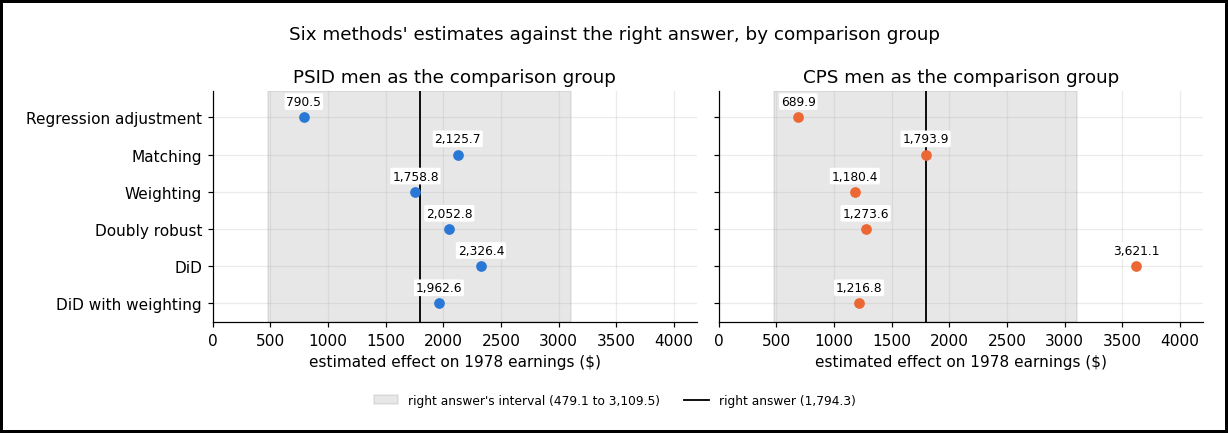

In [22]:
names = NAMES[1:]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, label in zip(axes, ["PSID", "CPS"]):
    values = [ESTIMATES[(label, n)] for n in names]
    ax.axvspan(LOW, HIGH, color=common.GREY, alpha=0.2, label=f"right answer's interval ({num(LOW)} to {num(HIGH)})")
    ax.axvline(RIGHT, color="black", lw=1.2, label=f"right answer ({num(RIGHT)})")
    ax.scatter(values, range(len(names)), color=common.BLUE if label == "PSID" else common.ORANGE, zorder=3)
    for y, v in enumerate(values):
        ax.annotate(f"{num(v)}", (v, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"), zorder=4)
    ax.set_yticks(range(len(names)), names)
    ax.set_ylim(len(names) - 0.5, -0.7)
    ax.set_xlim(0, 4200)
    ax.set_title(f"{label} men as the comparison group")
    ax.set_xlabel("estimated effect on 1978 earnings ($)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=8, frameon=False)
fig.suptitle("Six methods' estimates against the right answer, by comparison group")
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

**[only in this module]** Is the method closest to the right answer with the PSID men also the closest with the CPS men? The output ranks the six methods other than the naive gap by the size of the miss, ignoring its sign, for each group: if one method were best, it would rank 1 with both groups.

In [23]:
ranking = {"rank": range(1, len(names) + 1)}
for label in ["PSID", "CPS"]:
    misses = sorted(((abs(r1(ESTIMATES[(label, n)] - RIGHT)), n) for n in names))
    ranking[f"{label} men: method"] = [n for _, n in misses]
    ranking[f"{label} men: size of miss"] = [f"{num(m)}" for m, _ in misses]
print("Methods by size of miss, smallest first")
print()
common.show(pd.DataFrame(ranking))

Methods by size of miss, smallest first

rank  PSID men: method       PSID men: size of miss  CPS men: method        CPS men: size of miss
   1  Weighting                                35.5  Matching                                 0.4
   2  DiD with weighting                      168.3  Doubly robust                          520.7
   3  Doubly robust                           258.5  DiD with weighting                     577.5
   4  Matching                                331.4  Weighting                              613.9
   5  DiD                                     532.1  Regression adjustment                1,104.4
   6  Regression adjustment                 1,003.8  DiD                                  1,826.8


**Observation:**
- The naive gap misses by far the most with both groups: the PSID men and the CPS men earned much more in 1978 than the treated men.
- Every other estimate lands inside the right answer's interval, except DiD's with the CPS men: $3,621.1, a miss of $1,826.8.
- Weighting ranks 1 with the PSID men, with a miss of $35.5, and 4 with the CPS men, with $613.9. Matching ranks 1 with the CPS men, with $0.4, and 4 with the PSID men, with $331.4.
Inside the interval, the order could be chance. Chosen example: if the true effect were $800.0, regression adjustment, ranked 6 with the PSID men and 5 with the CPS men, would be the closest with both groups ($790.5 and $689.9).

**Conclusion:** no method ranks 1 with both groups, so the scoreboard names no best method, and the right answer rules out only the estimates outside its interval: the naive gap with both groups, and DiD with the CPS men.

### Where does DiD's miss come from?

**[only in this module]** DiD assumes the treated men's earnings, without the program, would have changed as much as the comparison men's did: the parallel-trends assumption. The lottery men show the treated men's change without the program, so the gap between the lottery men's change and the comparison men's change measures how far the assumption is off.

In [24]:
ch_l = r1(r1(lottery.re78.mean()) - r1(lottery.re75.mean()))
print(f"Lottery men's mean change ({len(lottery)} men)")
print("    = (lottery men's mean 1978 earnings) − (lottery men's mean 1975 earnings)")
print(f"    = {num(r1(lottery.re78.mean()))} − {num(r1(lottery.re75.mean()))} = {num(ch_l)}")
for label, data in [("PSID", psid), ("CPS", cps)]:
    c = data[data.treat == 0]
    ch_c = r1(r1(c.re78.mean()) - r1(c.re75.mean()))
    print()
    print(f"How far DiD's assumption is off = parallel-trends gap, {label} men ({len(lottery)} lottery men, {len(c):,} {label} men)")
    print(f"    = (lottery men's mean change) − ({label} men's mean change)")
    print(f"    = {num(ch_l)} − {num(ch_c)} = {num(r1(ch_l - ch_c))}")

Lottery men's mean change (260 men)
    = (lottery men's mean 1978 earnings) − (lottery men's mean 1975 earnings)
    = 4,554.8 − 1,266.9 = 3,287.9

How far DiD's assumption is off = parallel-trends gap, PSID men (260 lottery men, 2,490 PSID men)
    = (lottery men's mean change) − (PSID men's mean change)
    = 3,287.9 − 2,490.6 = 797.3

How far DiD's assumption is off = parallel-trends gap, CPS men (260 lottery men, 15,992 CPS men)
    = (lottery men's mean change) − (CPS men's mean change)
    = 3,287.9 − 1,195.9 = 2,092.0


**[only in this module]** The chart shows the same changes. Each group's line starts at 0 in 1975 and ends at its change by 1978, so the three lines can be compared directly, though the groups earned very different amounts. The vertical gaps at 1978 are the two parallel-trends gaps.

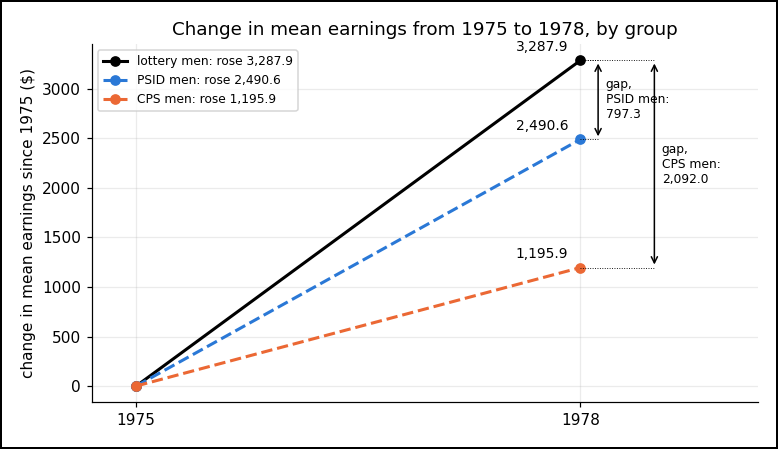

In [25]:
fig, ax = plt.subplots(figsize=(7, 4))
lines = [("lottery men", lottery, "black", "-"), ("PSID men", psid[psid.treat == 0], common.BLUE, "--"),
         ("CPS men", cps[cps.treat == 0], common.ORANGE, "--")]
ends = {}
for name, group, color, style in lines:
    rise = r1(r1(group.re78.mean()) - r1(group.re75.mean()))
    ends[name] = rise
    ax.plot([1975, 1978], [0, rise], color=color, ls=style, lw=2, marker="o", label=f"{name}: rose {num(rise)}")
    ax.annotate(num(rise), (1978, rise), textcoords="offset points", xytext=(-8, 6), ha="right", fontsize=9)
for name in ["PSID men", "CPS men"]:
    gap = r1(ends["lottery men"] - ends[name])
    x = 1978.12 if name == "PSID men" else 1978.5
    ax.plot([1978, x], [ends[name]] * 2, color="black", lw=0.6, ls=":")
    ax.plot([1978, x], [ends["lottery men"]] * 2, color="black", lw=0.6, ls=":")
    ax.annotate("", xy=(x, ends[name]), xytext=(x, ends["lottery men"]), arrowprops=dict(arrowstyle="<->", color="black", lw=1))
    ax.text(x + 0.05, (ends[name] + ends["lottery men"]) / 2, f"gap,\n{name}:\n{num(gap)}", ha="left", va="center", fontsize=8)
ax.set_xticks([1975, 1978])
ax.set_xlim(1974.7, 1979.2)
ax.set_ylabel("change in mean earnings since 1975 ($)")
ax.set_title("Change in mean earnings from 1975 to 1978, by group")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**Observation:** from 1975 to 1978, the lottery men's mean earnings rose $3,287.9. The CPS men's rose $1,195.9, so the parallel-trends gap is $2,092.0. The PSID men's rose $2,490.6, a gap of $797.3.

**Conclusion:** the comparison men's change differs from the lottery men's change with both groups, by more with the CPS men.

**[only in this module]** DiD's miss splits into two parts:
- the parallel-trends gap, from the output above
- the 1975 difference: how much more the treated men earned in 1975 than the lottery men

**formula**: DiD's miss = DiD estimate − right answer

**formula**: DiD estimate = (treated men's mean 1978 earnings − treated men's mean 1975 earnings) − (comparison men's mean 1978 earnings − comparison men's mean 1975 earnings)

**formula**: right answer = treated men's mean 1978 earnings − lottery men's mean 1978 earnings

1.
   DiD's miss =<br>
   &nbsp;&nbsp;&nbsp;&nbsp;= DiD estimate − right answer =<br>
   &nbsp;&nbsp;&nbsp;&nbsp;= (treated men's mean 1978 earnings − treated men's mean 1975 earnings) − (comparison men's mean 1978 earnings − comparison men's mean 1975 earnings) − (treated men's mean 1978 earnings − lottery men's mean 1978 earnings)

2. − (treated men's mean 1978 earnings − lottery men's mean 1978 earnings) =<br>
   &nbsp;&nbsp;&nbsp;&nbsp;= − treated men's mean 1978 earnings + lottery men's mean 1978 earnings

   The treated men's mean 1978 earnings is then added once and subtracted once, so it drops out:

   DiD's miss =<br>
   &nbsp;&nbsp;&nbsp;&nbsp;= ~~treated men's mean 1978 earnings~~ − treated men's mean 1975 earnings − (comparison men's mean 1978 earnings − comparison men's mean 1975 earnings) ~~− treated men's mean 1978 earnings~~ + lottery men's mean 1978 earnings =<br>
   &nbsp;&nbsp;&nbsp;&nbsp;= (lottery men's mean 1978 earnings − treated men's mean 1975 earnings) − (comparison men's mean 1978 earnings − comparison men's mean 1975 earnings)

3. Start from step 2's result. Inside the first bracket, subtract the lottery men's mean 1975 earnings and add it back, which doesn't change the total. Then take the last two terms out of the first bracket, and write them as one bracket with a minus in front:

   DiD's miss =<br>
   &nbsp;&nbsp;&nbsp;&nbsp;= (lottery men's mean 1978 earnings − treated men's mean 1975 earnings) − (comparison men's mean 1978 earnings − comparison men's mean 1975 earnings) =<br>
   &nbsp;&nbsp;&nbsp;&nbsp;= (lottery men's mean 1978 earnings − lottery men's mean 1975 earnings + lottery men's mean 1975 earnings − treated men's mean 1975 earnings) − (comparison men's mean 1978 earnings − comparison men's mean 1975 earnings) =<br>
   &nbsp;&nbsp;&nbsp;&nbsp;= (lottery men's mean 1978 earnings − lottery men's mean 1975 earnings) − (comparison men's mean 1978 earnings − comparison men's mean 1975 earnings) + lottery men's mean 1975 earnings − treated men's mean 1975 earnings =<br>
   &nbsp;&nbsp;&nbsp;&nbsp;= (lottery men's mean 1978 earnings − lottery men's mean 1975 earnings) − (comparison men's mean 1978 earnings − comparison men's mean 1975 earnings) − (treated men's mean 1975 earnings − lottery men's mean 1975 earnings)

4. Group the first two brackets:

   DiD's miss =<br>
   &nbsp;&nbsp;&nbsp;&nbsp;= (parallel-trends gap) − (1975 difference)

   where:

   parallel-trends gap =<br>
   &nbsp;&nbsp;&nbsp;&nbsp;= (lottery men's mean 1978 earnings − lottery men's mean 1975 earnings) − (comparison men's mean 1978 earnings − comparison men's mean 1975 earnings)

   as in the output above, and:

   1975 difference =<br>
   &nbsp;&nbsp;&nbsp;&nbsp;= treated men's mean 1975 earnings − lottery men's mean 1975 earnings

   how much more the treated men earned in 1975 than the lottery men. The lottery made the two groups differ only by chance, so the 1975 difference is chance.

In [26]:
t75, l75 = r1(treated.re75.mean()), r1(lottery.re75.mean())
gap75 = r1(t75 - l75)
print(f"1975 difference ({len(treated)} treated men, {len(lottery)} lottery men)")
print("    = (treated men's mean 1975 earnings) − (lottery men's mean 1975 earnings)")
print(f"    = {num(t75)} − {num(l75)} = {num(gap75)}")
for label, gap in [("PSID", r1(ch_l - r1(r1(psid[psid.treat == 0].re78.mean()) - r1(psid[psid.treat == 0].re75.mean())))),
                   ("CPS", r1(ch_l - r1(r1(cps[cps.treat == 0].re78.mean()) - r1(cps[cps.treat == 0].re75.mean()))))]:
    print()
    print(f"DiD's miss, {label} men")
    print("    = (parallel-trends gap) − (1975 difference)")
    print(f"    = {num(gap)} − {num(gap75)} = {num(r1(gap - gap75))}")

1975 difference (185 treated men, 260 lottery men)
    = (treated men's mean 1975 earnings) − (lottery men's mean 1975 earnings)
    = 1,532.1 − 1,266.9 = 265.2

DiD's miss, PSID men
    = (parallel-trends gap) − (1975 difference)
    = 797.3 − 265.2 = 532.1

DiD's miss, CPS men
    = (parallel-trends gap) − (1975 difference)
    = 2,092.0 − 265.2 = 1,826.8


**Observation:** the 1975 difference is $265.2. DiD's miss is $1,826.8 with the CPS men and $532.1 with the PSID men: the same misses as in the scoreboard.

**Conclusion:** DiD's miss comes from its assumption being wrong, not from chance: the comparison men's earnings didn't change as much as the treated men's would have without the program.

## Part 2: the guide, which method when

Part 1 showed that the scoreboard names no best method, so a ranking can't choose the method. What decides is the shape of the data: each method can run only on a certain shape, and rests on an assumption that has its own check. The checks then decide which estimate to trust.

Part 2 says "unit" for whatever the data's rows are, such as a man, a user, a city or a state, and "untreated group" for the comparison group.

Terms the checks use:
- A check's estimate "should be 0, apart from chance": its 95% confidence interval should include 0.
- A placebo outcome is an outcome the treatment couldn't change, such as earnings in a year before the program. Its estimate should be 0, apart from chance.
- A stand-in group is a group that didn't get the treatment but is like the treated group, such as applicants a lottery kept out. The method is run with the stand-in group in place of the treated group, against the untreated group. Its estimate should be 0, apart from chance.
- The move from leaving out a column is how far the estimate moves when one column is left out. A column the data doesn't have could differ between the groups and affect the outcome as much as the strongest column in the data does, so it could move the estimate as far. The check has no fixed pass rule. If leaving out one column in the data moves the estimate past 0, a missing column could too, and the estimate is fragile.
- Overlap: every treated unit has untreated units with a similar propensity score. Balance, by the size test from Module 4, matching: after matching or weighting, each column's mean is about the same in the two groups. Size = (difference in the column's mean) ÷ (the column's standard deviation among the treated units). A column passes if its size, ignoring the sign, is under 0.1.

**1. A randomized experiment (an A/B test)**
- The data has: units the analyst can split by chance.
- How it estimates: (the treated group's mean outcome) − (the untreated group's mean outcome).
- What must be true: chance alone decided who got the treatment.
- The check: the two groups' column means before the test should differ only by chance.

**2. RDD (regression discontinuity design)**
- The data has: a cutoff on a score that decides who gets the treatment.
- How it estimates: the jump in the outcome at the cutoff, between units just below and units just above.
- What must be true: nothing but the treatment changes at the cutoff, and units can't place themselves just past the cutoff.
- The check: the counts of units just below and just above the cutoff should differ only by chance. Fake cutoffs should show no jump in the outcome. An outcome the treatment can't change shouldn't jump at the cutoff.

**3. IV (instrumental variables)**
- The data has: an instrument, something that changes who gets the treatment and affects the outcome in no other way.
- How it estimates: (how much the instrument changes the outcome) ÷ (how much the instrument changes the treatment). The estimate is the effect on the units whose treatment the instrument changed, because only their outcomes, not other units' outcomes, move with the instrument.
- What must be true: the no-other-way rule, and the instrument moves the treatment strongly.
- The check: the F-statistic, which measures how strongly the instrument moves the treatment, should be above 10, the usual rule. The no-other-way rule can only be argued, not tested.

**4. Synthetic control**
- The data has: one treated unit, such as a state or a city, and many untreated units, with many periods before the treatment.
- How it estimates: it builds a weighted mix of untreated units whose outcome matched the treated unit's before the treatment. After the treatment, the estimate = (the treated unit's outcome) − (the mix's outcome).
- What must be true: the mix's outcome would have kept matching the treated unit's after the treatment, had there been no treatment.
- The check: the mix's outcome should match the treated unit's closely before the treatment. Run the method on each untreated unit as if it were treated (a placebo unit). Each placebo unit's gap after the treatment should be smaller than the treated unit's.
  - Fake treatment year: pick a year before the real treatment, and build the treated unit's mix only from the years before it. There is no treatment yet, so the gap between the treated unit's outcome and its mix's outcome should stay as small as before the fake year.
  - Leave one out: rebuild the treated unit's mix without one untreated unit, once for each unit. The estimate shouldn't rest on any one untreated unit, so each new estimate should stay close to the estimate from the full mix.

**5. DiD**
- The data has: the outcome before and after the treatment, for the treated group and an untreated group.
- How it estimates: (the treated group's change) − (the untreated group's change).
- What must be true: without the treatment, the treated group's outcome would have changed as much as the untreated group's (parallel trends).
- DiD with weighting, from Part 1, is DiD with weighting's weights on the untreated group.
- The check: in each period before the treatment, the two groups' outcomes should change by the same amount, apart from chance.

**6. Regression adjustment, matching, weighting, doubly robust**
- The data has: only columns measured before the treatment, for the treated group and an untreated group.
- How it estimates:
  - Regression adjustment: fits a formula for the outcome on the untreated group, and uses it to predict each treated unit's outcome without the treatment.
  - Matching: pairs each treated unit with the untreated unit whose propensity score is closest.
  - Weighting: weights each untreated unit by (its propensity score) ÷ (1 − its propensity score).
  - Doubly robust: regression adjustment, corrected with weighting.
- What must be true: every difference between the groups that affects the outcome has a column, and overlap.
- The check: overlap and balance, a placebo outcome, a stand-in group, and the move from leaving out a column.

The diagram turns the six data shapes into six questions, asked in order. Every question gets asked, even after a yes, because the same data can fit several methods, as the NSW data fits both method 5 (DiD) and method 6 (regression adjustment, matching, weighting, doubly robust).

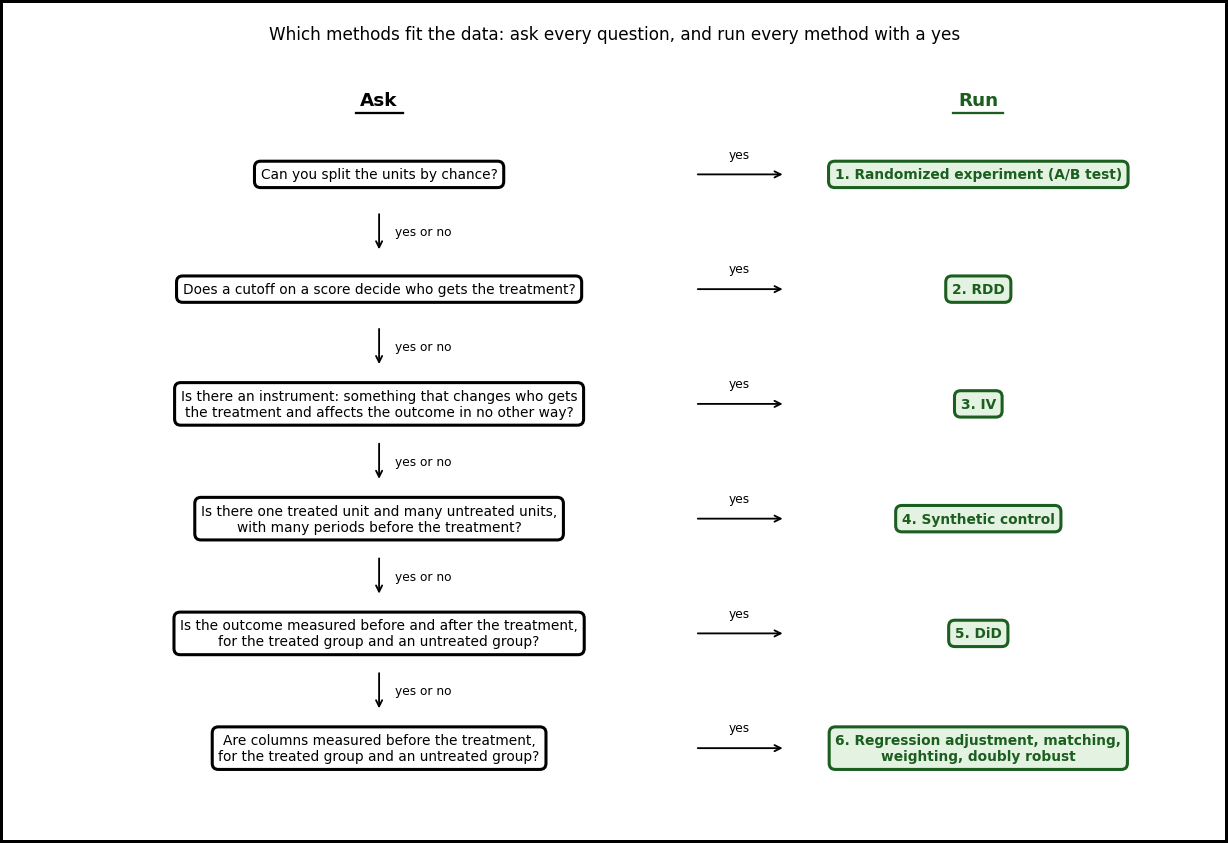

In [27]:
questions = [
    "Can you split the units by chance?",
    "Does a cutoff on a score decide who gets the treatment?",
    "Is there an instrument: something that changes who gets\nthe treatment and affects the outcome in no other way?",
    "Is there one treated unit and many untreated units,\nwith many periods before the treatment?",
    "Is the outcome measured before and after the treatment,\nfor the treated group and an untreated group?",
    "Are columns measured before the treatment,\nfor the treated group and an untreated group?",
]
methods = ["1. Randomized experiment (A/B test)", "2. RDD", "3. IV", "4. Synthetic control", "5. DiD",
           "6. Regression adjustment, matching,\nweighting, doubly robust"]
fig, ax = plt.subplots(figsize=(11, 7.5))
ax.set_xlim(0, 11)
ax.set_ylim(-0.6, len(questions) + 0.1)
headers = [ax.text(3.3, len(questions) - 0.35, "Ask", ha="center", va="center", fontsize=12, fontweight="bold"),
           ax.text(8.9, len(questions) - 0.35, "Run", ha="center", va="center", fontsize=12, fontweight="bold", color="#1b5e20")]
fig.canvas.draw()
for h in headers:  # underline each header, as wide as its text
    (x0, y0), (x1, _) = ax.transData.inverted().transform(h.get_window_extent())
    ax.plot([x0, x1], [y0 - 0.02] * 2, color=h.get_color(), lw=1.5)
ax.axis("off")
box = dict(boxstyle="round,pad=0.45", ec="black", lw=1)
for i, (q, m) in enumerate(zip(questions, methods)):
    y = len(questions) - 1 - i
    ax.text(3.3, y, q, ha="center", va="center", fontsize=9, bbox={**box, "fc": "white", "lw": 2})
    ax.text(8.9, y, m, ha="center", va="center", fontsize=9, fontweight="bold", color="#1b5e20",
            bbox={**box, "fc": "#e3f2e1", "ec": "#1b5e20", "lw": 2})
    ax.annotate("", xy=(7.1, y), xytext=(6.25, y), arrowprops=dict(arrowstyle="->", lw=1.2))
    ax.text(6.67, y + 0.12, "yes", ha="center", va="bottom", fontsize=8)
    if i < len(questions) - 1:
        ax.annotate("", xy=(3.3, y - 0.68), xytext=(3.3, y - 0.32), arrowprops=dict(arrowstyle="->", lw=1.2))
        ax.text(3.45, y - 0.5, "yes or no", ha="left", va="center", fontsize=8)
ax.set_title("Which methods fit the data: ask every question, and run every method with a yes", fontsize=11)
plt.tight_layout()
plt.show()

How to use the guide:
1. Find every method whose data shape the data has. The same data can fit several: the NSW data, with 1975 and 1978 earnings for both groups, fits both method 5 and method 6.
2. Run every method that fits, and run each method's check.
3. Trust an estimate only as far as its method's assumption survives its check. Part 1 graded the methods with the right answer instead, which a real analyst can't do. When two methods' estimates differ widely, at least one of them likely rests on an assumption that fails. The checks can warn which one, but no check can prove the other right.

## Exercise — five product cases

Each case describes a question and the data an analyst has. No numbers are needed.

### Questions

1. An app gives sellers a "top seller" badge once their rating reaches 4.5 stars. Did the badge raise their sales? The data: every seller's rating and monthly sales.
2. A delivery fee started in one city out of 40 the app serves. Did the fee cut orders in that city? The data: weekly orders in each of the 40 cities for the 3 years before the fee and the 6 months after.
3. A feature launched for all Android users in March, and iOS users never got it. Did the feature raise spend? The data: weekly spend of both groups from January to June.
4. Users who turned on notifications spend more than users who didn't. Did turning them on raise spend? The app added notifications a year ago. The data: each user's monthly spend in the year before the app added notifications and in the year since, sign-up date, country, and whether the user turned notifications on. Nothing decided who turned them on except the users themselves.
5. A test sent a reminder email about feature X to a random half of users. Only some of them opened the email and used feature X. Did using feature X raise how many users kept using the app 30 days later? The data: who got the email, who used feature X, and who kept using the app.

For each case: which method/s, what must be true, and which check?

### Answers

**Answer 1.** RDD, because a cutoff on a score, the 4.5-star rating, decides who gets the badge.
- What must be true: nothing but the badge changes at 4.5 stars, and sellers can't push their rating to just past 4.5.
- The check: count the sellers just below and just above 4.5. Many more just above than chance would give would mean sellers push their rating past the cutoff. Fake cutoffs, such as 4.3 and 4.7, should show no jump in sales.

**Answer 2.** Synthetic control, because one city got the fee and 39 cities didn't, with 3 years of orders before the fee.
- What must be true: a weighted mix of the 39 cities whose weekly orders matched the city's before the fee would have kept matching them after, had there been no fee.
- The check: the fit before the fee, each of the 39 cities run as a placebo city, a fake fee date before the real one, and leaving out one city at a time from the mix.

**Answer 3.** DiD, because both groups have spend before and after March.
- What must be true: without the feature, Android users' spend would have changed by as much as iOS users'.
- The check: the two groups' trends from January to March, before the launch. A gap that grows before March fails the check.

**Answer 4.** Two methods fit, as with the NSW data. Method 6 (regression adjustment, matching, weighting, doubly robust), because the data has columns measured before notifications existed. Method 5 (DiD), because the data has spend before and since for both groups of users.
- What must be true for method 6: every difference between the two groups of users that affects spend has a column. The data has no column for how engaged each user already was, and engaged users may both turn notifications on and spend more.
- What must be true for DiD: without notifications, the two groups' spend would have changed by the same amount.
- The checks for method 6: overlap and balance, a placebo outcome, and the move from leaving out each column. The placebo outcome: spend in the earliest month of the year before notifications existed, with that month left out of the columns. Notifications can't have changed that spend, so its estimate should be 0, apart from chance.
- The check for DiD: in each month of the year before notifications existed, the two groups' spend should change by the same amount, apart from chance.

**Answer 5.** IV, with the random email as the instrument, because the email changes who uses feature X, and the lottery that picked who got the email makes the email unrelated to the users' traits.
- What must be true: the email changes whether users keep using the app only through feature X, and it moves the use of feature X strongly.
- The estimate is the effect on the users whom the email moved to use feature X, not on every user of feature X, as the guide's method 3 (IV) says.
- The check: the F-statistic for strength. The no-other-way rule can only be argued: an email that reminds users the app exists could keep them using the app by itself, without feature X, which would break the rule.

**What the answers show:** each case's data has a shape that points to its method. Case 4 fits two methods, so both get run, and each method's checks show whether its assumption holds up.

## Interview angle

> "Two methods on the same data give 2% and 9%. Which one do you report?"

A strong answer: neither, until each method's assumption is checked. The two methods rest on different assumptions, so a gap as wide as 2% to 9% likely means at least one assumption fails.

- Name each method's assumption. For example, matching assumes every difference between the groups has a column, and DiD assumes parallel trends.
- Run each method's check: the trends before the treatment for DiD, and a placebo outcome and the move from leaving out a column for matching.
- Report the estimate whose method passes its checks, and say why the other one failed. If both pass, the gap could be chance or a failed assumption the checks missed: report both, 2% and 9%, each with its assumption, and say the data can't settle it.
- Never pick the number closer to what was expected: an expected number isn't a right answer, and even a right answer can't rank estimates inside its interval.

## Key takeaways

- The right answer from the lottery is $1,794.3, and it is itself an estimate, with a 95% confidence interval from $479.1 to $3,109.5. The interval doesn't say where inside it the true effect is, so the right answer can't rank estimates inside the interval.
- No method was closest with both comparison groups: weighting was closest with the PSID men and fourth with the CPS men, and matching the reverse. Only the naive gaps and DiD's estimate with the CPS men, a miss of $1,826.8, landed outside the interval.
- DiD missed with the CPS men because its parallel-trends assumption broke: the CPS men's earnings rose $2,092.0 less than the lottery men's from 1975 to 1978. DiD's miss = (parallel-trends gap) − (1975 difference) = $2,092.0 − $265.2 = $1,826.8.
- So these two comparison groups can't name a best method. The data's shape decides which methods can run: a cutoff, an instrument, one treated unit among many, before and after measures, or only columns measured before.
- When several methods fit, run each and check each method's assumption. Trust an estimate only as far as its assumption survives its checks.